#  Classification des étoiles — pipeline complet de data science

**Pipeline suivi : `Data → EDA → Prétraitement → ML → EVAL → Deploy`**

Ce notebook reprend l'analyse visuelle d'origine (jeu de données « Stars », 240 étoiles) et la complète pour couvrir **toutes** les étapes d'un projet de data science.

| # | Étape du pipeline | Sections du notebook | Ce qui vient du notebook d'origine | Ce qui a été ajouté |
|---|---|---|---|---|
| 1 | **Data** | §1 Chargement, typage, audit qualité | Chargement CSV, `info`, `describe`, dictionnaire des variables | Détection des *vrais* manquants (cases « espace »), doublons, renommage, types corrects |
| 2 | **EDA** | §2 Analyse exploratoire | Barplots, boxplots, pairplot, diagramme HR | Échelles log, histogrammes par type, corrélations, tables croisées, test de cohérence physique, PCA |
| 3 | **Prétraitement** | §3 Nettoyage, features, split, transformateurs | Remplissage des NaN (mode / moyenne) | Imputation sans fuite de données (dans un `Pipeline`), log-transform, encodage one-hot, split stratifié |
| 4 | **ML** | §4 Modélisation | — *(absent)* | Baseline, 5 modèles en validation croisée, réglage d'hyperparamètres, clustering non supervisé |
| 5 | **EVAL** | §5 Évaluation | — *(absent)* | Métriques sur le jeu de test, matrice de confusion, importance des variables, analyse d'erreurs |
| 6 | **Deploy** | §6 Déploiement | Sauvegarde des figures (zip) | Sauvegarde du modèle, module `star_predictor.py`, application Streamlit, `requirements.txt` |

In [1]:
import warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

DATA_PATH = Path("cleaned_star_data.csv")
PLOTS = Path("star_plots"); PLOTS.mkdir(exist_ok=True)
MODELS = Path("models");    MODELS.mkdir(exist_ok=True)

STAR_TYPES = {0: "Brown Dwarf", 1: "Red Dwarf", 2: "White Dwarf",
              3: "Main Sequence", 4: "Supergiant", 5: "Hypergiant"}
TYPE_ORDER = list(STAR_TYPES.values())
TYPE_COLORS = {"Brown Dwarf": "#8c564b", "Red Dwarf": "#d62728", "White Dwarf": "#7f7f7f",
               "Main Sequence": "#17becf", "Supergiant": "#ff7f0e", "Hypergiant": "#9467bd"}

---
# 1️ DATA — Collecte et audit de la qualité

**Objectif de l'étape** : charger les données, vérifier leur structure et mesurer leur qualité *avant* toute analyse.

### Dictionnaire des variables
| Variable (CSV) | Nom utilisé ici | Description |
|---|---|---|
| Temperature (K) | `temperature_k` | Température de surface (K) |
| Luminosity(L/Lo) | `luminosity` | Luminosité relative au Soleil (L☉ = 3,828·10²⁶ W) |
| Radius(R/Ro) | `radius` | Rayon relatif au Soleil (R☉ = 6,9551·10⁸ m) |
| Absolute magnitude(Mv) | `abs_mag` | Magnitude absolue |
| Star color | `color` | Couleur observée |
| Spectral Class | `spectral_class` | Classe spectrale (O, B, A, F, G, K, M) |
| Star type | `star_type` | **Cible** : 0 Brown Dwarf · 1 Red Dwarf · 2 White Dwarf · 3 Main Sequence · 4 Supergiant · 5 Hypergiant |

>  **Piège du notebook d'origine** : dans le CSV, les valeurs manquantes sont des cases contenant un *espace* (`" "`), que pandas lit comme du texte et non comme `NaN`. `df.isnull()` indiquait donc « 0 manquant » à tort, et `fillna(mode)` ne remplissait rien. On les convertit explicitement en `NaN` ici.

In [2]:
RENAME = {"Temperature (K)": "temperature_k", "Luminosity(L/Lo)": "luminosity",
          "Radius(R/Ro)": "radius", "Absolute magnitude(Mv)": "abs_mag",
          "Star type": "star_type", "Star color": "color", "Spectral Class": "spectral_class"}
NUM = ["temperature_k", "luminosity", "radius", "abs_mag"]
CAT = ["color", "spectral_class"]
TARGET = "star_type"

# skipinitialspace + na_values : les cases " " deviennent de vrais NaN
raw = pd.read_csv(DATA_PATH, skipinitialspace=True, na_values=["", " "])
print("Lignes lues :", len(raw), "| lignes entièrement vides :", raw.isna().all(axis=1).sum())

df = (raw.dropna(how="all").rename(columns=RENAME).reset_index(drop=True))
df[NUM] = df[NUM].apply(pd.to_numeric, errors="coerce")
df[TARGET] = df[TARGET].astype(int)
for c in CAT:
    df[c] = df[c].str.strip()
df["star_type_name"] = df[TARGET].map(STAR_TYPES)
df.head()

Lignes lues : 240 | lignes entièrement vides : 1


,temperature_k,luminosity,radius,abs_mag,star_type,color,spectral_class,star_type_name
0,3042.0,0.000500,0.1542,16.60,0,Red,M,Brown Dwarf
1,2600.0,0.000300,0.1020,18.70,0,Red,M,Brown Dwarf
2,2800.0,0.000200,NaN,16.65,0,Red,M,Brown Dwarf
3,1939.0,0.000138,0.1030,20.06,0,Red,M,Brown Dwarf
4,2840.0,NaN,0.1100,16.98,0,Red,M,Brown Dwarf


In [5]:
df.info()
print("\nForme :", df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 239 entries, 0 to 238
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   temperature_k   237 non-null    float64
 1   luminosity      233 non-null    float64
 2   radius          232 non-null    float64
 3   abs_mag         234 non-null    float64
 4   star_type       239 non-null    int64  
 5   color           233 non-null    object 
 6   spectral_class  237 non-null    object 
 7   star_type_name  239 non-null    object 
dtypes: float64(4), int64(1), object(3)
memory usage: 15.1+ KB

Forme : (239, 8)


In [6]:
# Audit des valeurs manquantes (réelles)
missing = pd.DataFrame({"manquants": df.isna().sum(), "%": (df.isna().mean() * 100).round(2)})
display(missing[missing["manquants"] > 0])
print("Lignes avec au moins une valeur manquante :", df.isna().any(axis=1).sum(), "/", len(df))

# Doublons, cardinalité des catégories
print("Doublons exacts :", df.duplicated().sum())
print("\nModalités de 'color'         :", sorted(df['color'].dropna().unique()))
print("Modalités de 'spectral_class':", sorted(df['spectral_class'].dropna().unique()))

,manquants,%
temperature_k,2,0.84
luminosity,6,2.51
radius,7,2.93
abs_mag,5,2.09
color,6,2.51
spectral_class,2,0.84


Lignes avec au moins une valeur manquante : 24 / 239
Doublons exacts : 0

Modalités de 'color'         : ['Blue', 'Blue-White', 'Red', 'White', 'Yellow-White']
Modalités de 'spectral_class': ['A', 'B', 'F', 'G', 'K', 'M', 'O']


**Constats de l'étape Data**
- 239 étoiles exploitables (la 1ʳᵉ ligne du CSV est vide), **quasi parfaitement équilibrées** : 40 étoiles par type, sauf 39 pour les Brown Dwarf (voir §2.1).
- Les manquants sont peu nombreux mais répartis sur toutes les variables : ils seront traités dans le **prétraitement** (sans supprimer de lignes, le jeu étant petit).
- Aucune modalité en double sous différentes graphies dans `color` ; les noms sont cohérents.

---
# 2️ EDA — Analyse exploratoire

**Objectif de l'étape** : comprendre les distributions, les relations entre variables et la structure des classes, et repérer ce qu'il faudra corriger au prétraitement.

> L'EDA est faite sur les données *non imputées* : seaborn / pandas ignorent simplement les `NaN`, ce qui évite de fausser les distributions par une imputation prématurée.

### 2.1 Répartition de la cible *(d'après le notebook d'origine, cellules 25-26)*

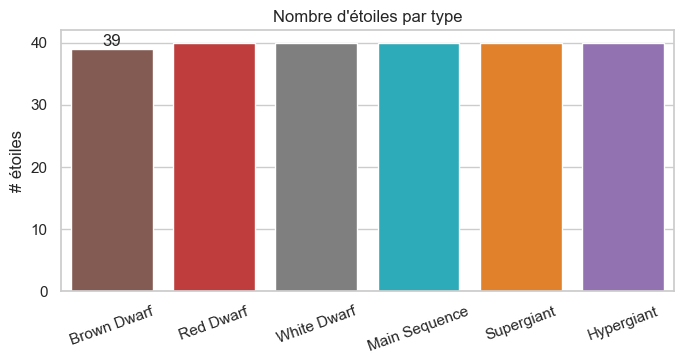

In [7]:
counts = df["star_type_name"].value_counts().reindex(TYPE_ORDER)
fig, ax = plt.subplots(figsize=(7, 3.8))
sns.barplot(x=counts.index, y=counts.values, palette=TYPE_COLORS, order=TYPE_ORDER, ax=ax)
ax.bar_label(ax.containers[0])
ax.set(title="Nombre d'étoiles par type", xlabel="", ylabel="# étoiles")
plt.xticks(rotation=20); plt.tight_layout()
plt.savefig(PLOTS / "01_star_count.png", dpi=150); plt.show()

### 2.2 Statistiques par type

In [8]:
stats = (df.groupby("star_type_name")[NUM]
           .agg(["median", "min", "max"]).reindex(TYPE_ORDER))
display(stats.style.format("{:.4g}"))

Les types s'étalent sur **plus de 9 ordres de grandeur** en luminosité (≈10⁻⁴ à ≈10⁶ L☉) et 5 en rayon. Des échelles linéaires écrasent donc la plupart des classes → on utilise des **échelles logarithmiques** à partir d'ici. (Le notebook d'origine traçait boxplots et pairplot en linéaire.)

### 2.3 Distributions par type (échelle log pour luminosité et rayon)

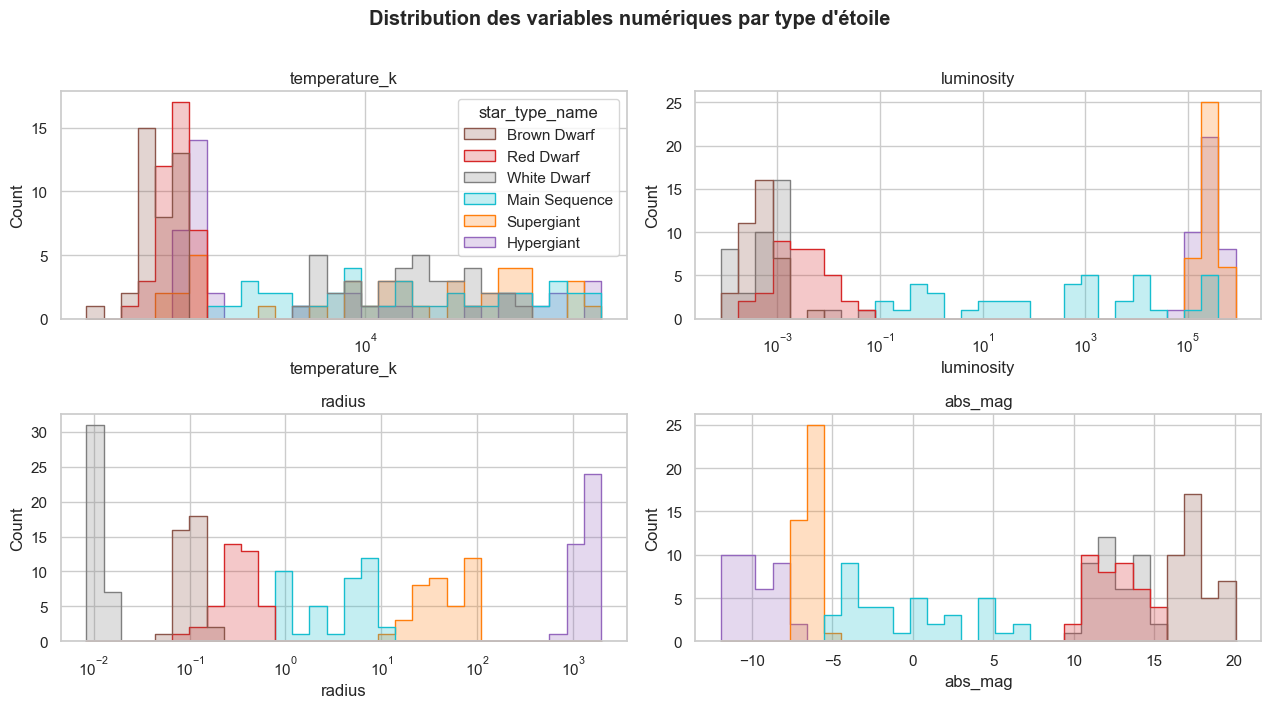

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, col in zip(axes.ravel(), NUM):
    sns.histplot(data=df, x=col, hue="star_type_name", hue_order=TYPE_ORDER, palette=TYPE_COLORS,
                 log_scale=(col in ["temperature_k", "luminosity", "radius"]),
                 element="step", bins=30, ax=ax, legend=(col == "temperature_k"))
    ax.set_title(col)
plt.suptitle("Distribution des variables numériques par type d'étoile", y=1.01, weight="bold")
plt.tight_layout(); plt.savefig(PLOTS / "02_histograms.png", dpi=150); plt.show()

### 2.4 Boxplots & valeurs extrêmes *(notebook d'origine, cellule 30, en échelle log)*

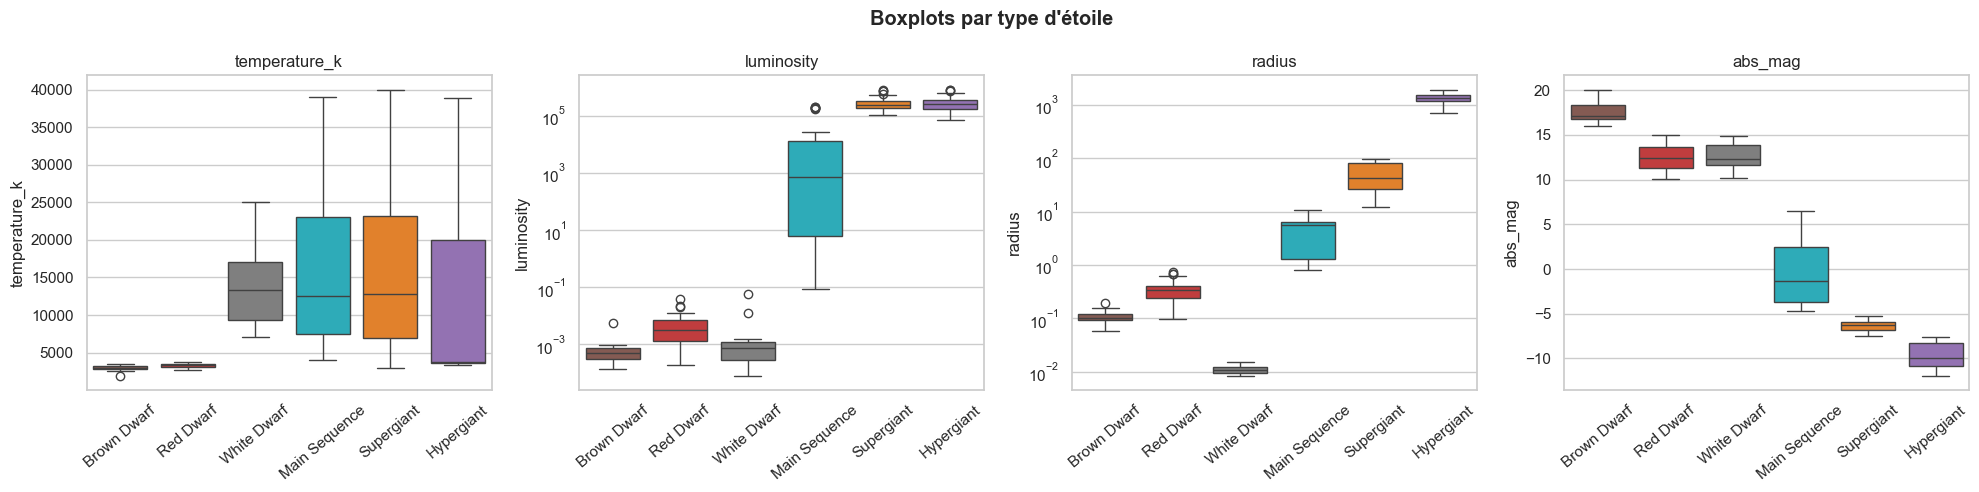

,temperature_k,luminosity,radius,abs_mag
"Valeurs aberrantes (IQR, par type)",,,,
Brown Dwarf,1,1,2,0
Red Dwarf,1,0,1,0
White Dwarf,0,2,0,0
Main Sequence,0,0,0,0
Supergiant,0,1,0,0
Hypergiant,0,0,1,0


In [10]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, col in zip(axes, NUM):
    sns.boxplot(data=df, x="star_type_name", y=col, order=TYPE_ORDER, palette=TYPE_COLORS, ax=ax)
    if col in ["luminosity", "radius"]:
        ax.set_yscale("log")
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=40)
plt.suptitle("Boxplots par type d'étoile", weight="bold"); plt.tight_layout()
plt.savefig(PLOTS / "03_boxplots.png", dpi=150); plt.show()

# Valeurs aberrantes (règle IQR) calculées PAR type sur l'échelle log
def iqr_outliers(s):
    x = np.log10(s) if s.name in ["luminosity", "radius", "temperature_k"] else s
    q1, q3 = x.quantile([.25, .75]); i = q3 - q1
    return ((x < q1 - 1.5 * i) | (x > q3 + 1.5 * i)).sum()
display(df.groupby("star_type_name")[NUM].agg(iqr_outliers).reindex(TYPE_ORDER)
          .rename_axis("Valeurs aberrantes (IQR, par type)"))

### 2.5 Relations entre variables *(pairplot d'origine, cellule 36, en log et coloré par type)*

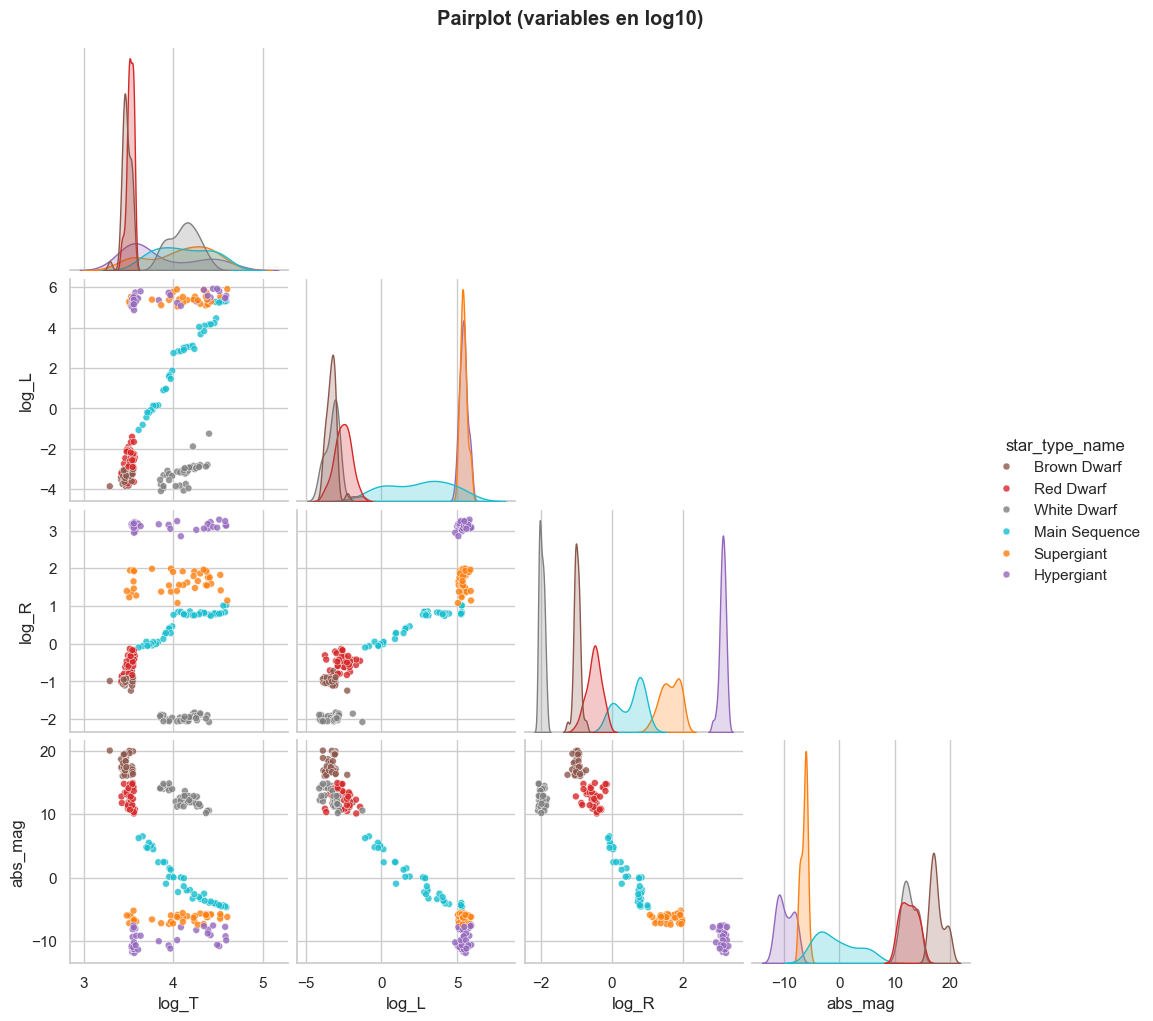

In [11]:
pp = df.assign(log_T=np.log10(df.temperature_k), log_L=np.log10(df.luminosity),
               log_R=np.log10(df.radius))[["log_T", "log_L", "log_R", "abs_mag", "star_type_name"]]
g = sns.pairplot(pp, hue="star_type_name", hue_order=TYPE_ORDER, palette=TYPE_COLORS,
                 corner=True, plot_kws=dict(s=25, alpha=.8))
g.figure.suptitle("Pairplot (variables en log10)", y=1.02, weight="bold")
g.savefig(PLOTS / "04_pairplot.png", dpi=130); plt.show()

### 2.6 Diagrammes de Hertzsprung-Russell *(cellule 39 d'origine, axes corrigés)*

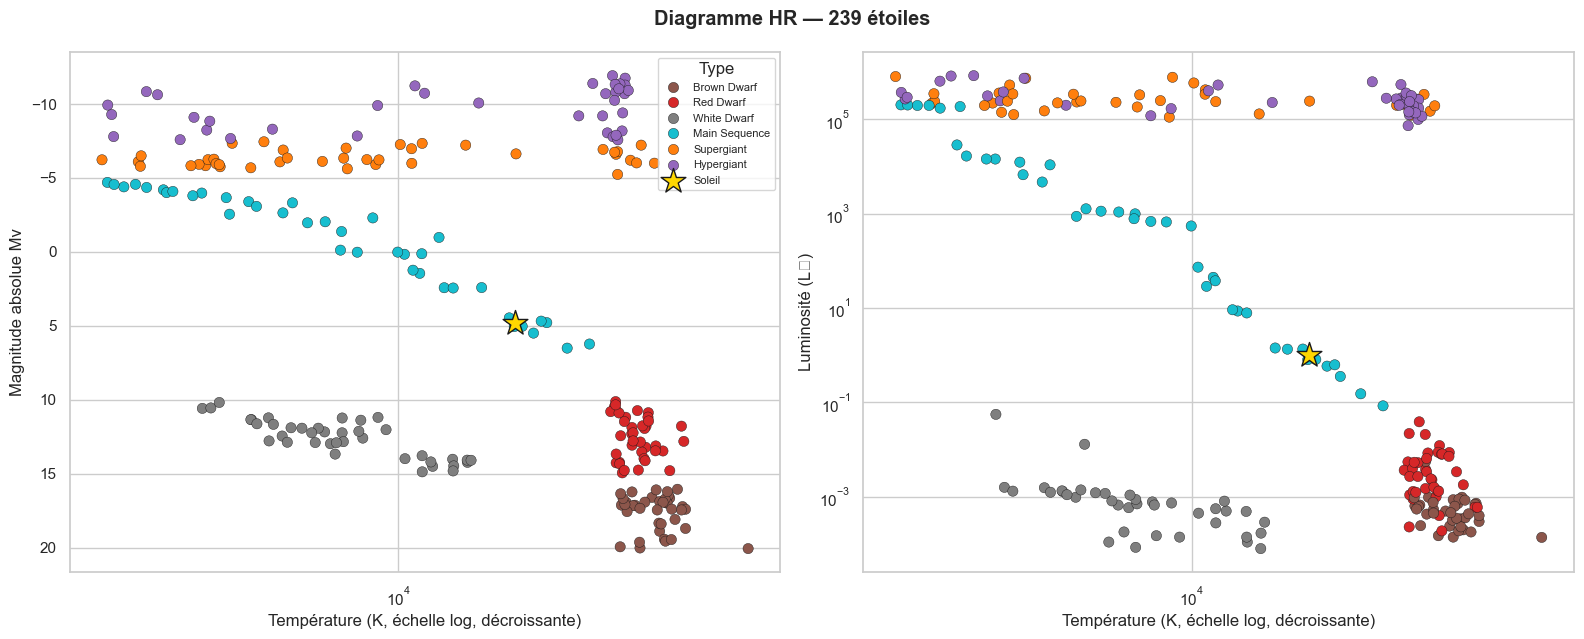

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (ycol, ylabel, logy) in zip(axes, [("abs_mag", "Magnitude absolue Mv", False),
                                          ("luminosity", "Luminosité (L☉)", True)]):
    sns.scatterplot(data=df, x="temperature_k", y=ycol, hue="star_type_name", hue_order=TYPE_ORDER,
                    palette=TYPE_COLORS, s=55, edgecolor="k", linewidth=.3, ax=ax)
    sun_y = 4.83 if ycol == "abs_mag" else 1.0
    ax.scatter(5778, sun_y, marker="*", s=350, c="gold", edgecolor="k", label="Soleil", zorder=5)
    ax.set_xscale("log"); ax.invert_xaxis()               # chaud à gauche
    if logy: ax.set_yscale("log")
    else:    ax.invert_yaxis()                            # brillant en haut
    ax.set(xlabel="Température (K, échelle log, décroissante)", ylabel=ylabel)
axes[0].legend(title="Type", fontsize=8); axes[1].legend().remove()
plt.suptitle(f"Diagramme HR — {len(df)} étoiles", weight="bold"); plt.tight_layout()
plt.savefig(PLOTS / "05_hr_diagram.png", dpi=150); plt.show()

On retrouve la structure attendue : la **séquence principale** en diagonale, les **naines blanches** en bas à gauche, les **géantes / hypergéantes** en haut. La séparation des classes est très nette en (T, L, R) → de bon augure pour la classification.

### 2.7 Corrélations

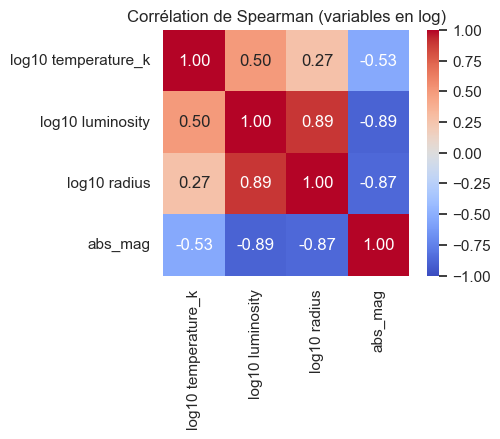

In [13]:
logs = df[NUM].copy()
for c in ["temperature_k", "luminosity", "radius"]:
    logs[c] = np.log10(logs[c])
logs = logs.rename(columns=lambda c: ("log10 " + c) if c != "abs_mag" else c)
corr = logs.corr(method="spearman")
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Corrélation de Spearman (variables en log)"); plt.tight_layout()
plt.savefig(PLOTS / "06_correlation.png", dpi=150); plt.show()

`abs_mag` est très fortement anticorrélée à `log luminosity` (ρ ≈ −0,9) (relation physique Mv ≈ 4,83 − 2,5·log L) → **forte redondance**, à garder en tête pour interpréter l'importance des variables.

### 2.8 Variables catégorielles

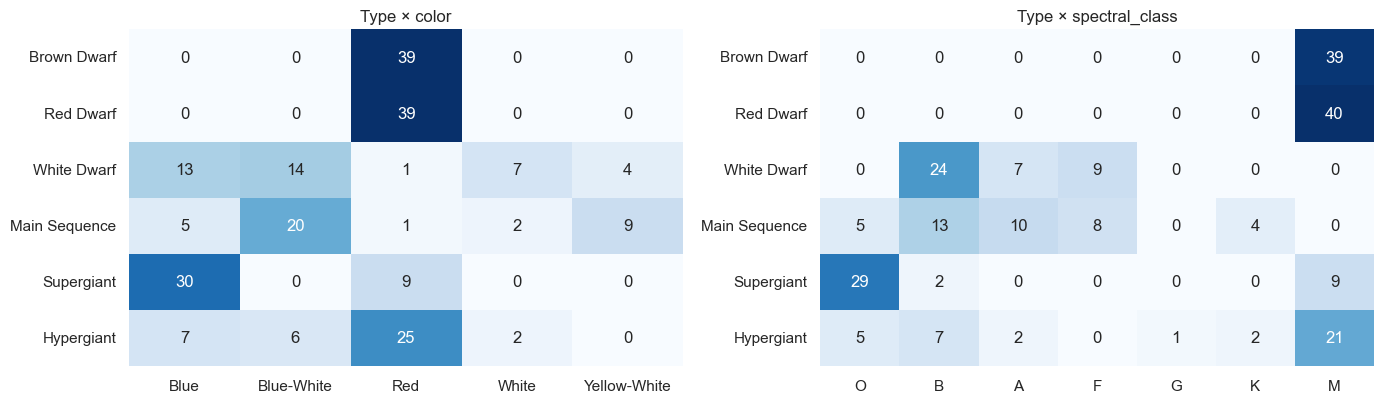

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, col, order in zip(axes, CAT, [None, ["O", "B", "A", "F", "G", "K", "M"]]):
    ct = pd.crosstab(df["star_type_name"], df[col]).reindex(TYPE_ORDER)
    if order: ct = ct.reindex(columns=[o for o in order if o in ct.columns])
    sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set(title=f"Type × {col}", ylabel="", xlabel="")
plt.tight_layout(); plt.savefig(PLOTS / "07_categorical.png", dpi=150); plt.show()

### 2.9 Cohérence physique & qualité des étiquettes

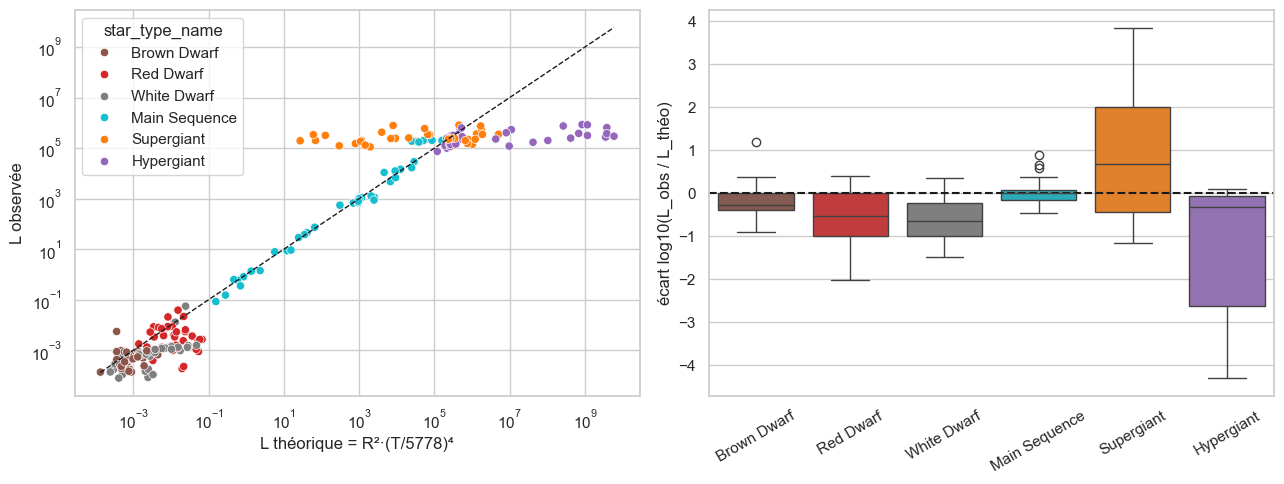

Étoiles s'écartant de plus d'un facteur 3 (0,5 dex) de la loi : 94 / 225
Classe spectrale incohérente avec la température (seuils usuels) : 24% des étoiles


In [15]:
# (a) Stefan-Boltzmann : L/L☉ = (R/R☉)² (T/5778 K)⁴
full = df.dropna(subset=["temperature_k", "luminosity", "radius"]).copy()
full["L_theo"] = full.radius**2 * (full.temperature_k / 5778)**4
full["dev_dex"] = np.log10(full.luminosity) - np.log10(full.L_theo)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=full, x="L_theo", y="luminosity", hue="star_type_name", hue_order=TYPE_ORDER,
                palette=TYPE_COLORS, ax=axes[0])
lim = [full.L_theo.min(), full.L_theo.max()]
axes[0].plot(lim, lim, "k--", lw=1, label="y = x (loi de Stefan-Boltzmann)")
axes[0].set(xscale="log", yscale="log", xlabel="L théorique = R²·(T/5778)⁴", ylabel="L observée")
sns.boxplot(data=full, x="star_type_name", y="dev_dex", order=TYPE_ORDER, palette=TYPE_COLORS, ax=axes[1])
axes[1].axhline(0, color="k", ls="--"); axes[1].tick_params(axis="x", rotation=30)
axes[1].set(ylabel="écart log10(L_obs / L_théo)", xlabel="")
plt.tight_layout(); plt.savefig(PLOTS / "08_stefan_boltzmann.png", dpi=150); plt.show()
print(f"Étoiles s'écartant de plus d'un facteur 3 (0,5 dex) de la loi : {(full.dev_dex.abs() > .5).sum()} / {len(full)}")

# (b) Classe spectrale vs température (seuils usuels)
def spectral_from_T(t):
    for lim, c in [(30000, "O"), (10000, "B"), (7500, "A"), (6000, "F"), (5200, "G"), (3700, "K")]:
        if t >= lim: return c
    return "M"
sub = df.dropna(subset=["temperature_k", "spectral_class"]).copy()
sub["expected"] = sub.temperature_k.map(spectral_from_T)
mismatch = (sub.expected != sub.spectral_class).mean()
print(f"Classe spectrale incohérente avec la température (seuils usuels) : {mismatch:.0%} des étoiles")

### Synthèse de l'EDA → décisions pour le prétraitement
1. **Les classes sont bien séparables** en (température, luminosité, rayon) → les modèles devraient atteindre de très bons scores.
2. **Luminosité et rayon** sont extrêmement asymétriques → **transformation log10** obligatoire pour les modèles sensibles à l'échelle (régression logistique, SVM, kNN).
3. **`abs_mag` ≈ f(log L)** → forte redondance ; on la conserve (info supplémentaire quand L manque) mais on interprétera l'importance avec prudence.
4. **Les données ne suivent pas parfaitement la physique** (écarts à Stefan-Boltzmann, classes spectrales/couleurs parfois incohérentes avec la température) : le jeu contient du bruit ou des erreurs. On **ne reconstruit donc pas** les manquants par formule physique ; on les impute statistiquement.
5. **`color` et `spectral_class`** sont catégorielles nominales → encodage **one-hot**. Elles sont bruitées, ce qui peut en limiter l'utilité.
6. **Jeu petit (≈240 lignes)** → validation croisée stratifiée, pas de suppression de lignes, résultats à interpréter avec prudence.

### 2.10 Projection PCA (exploratoire)

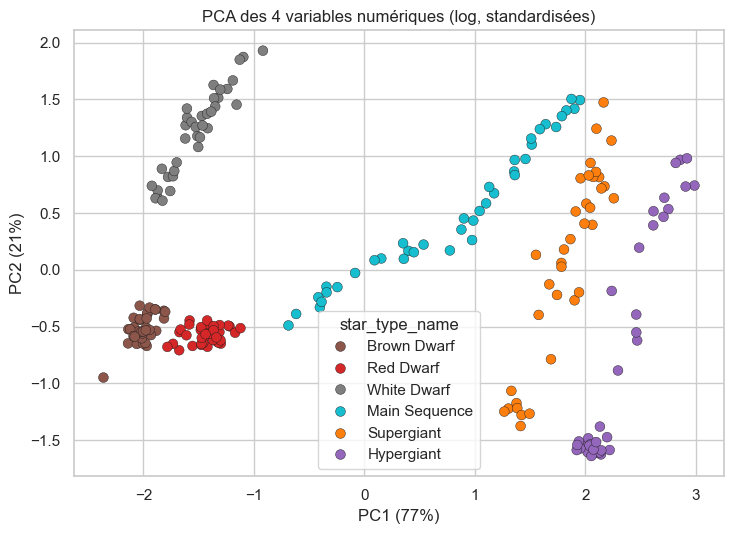

In [16]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
cc = df.dropna(subset=NUM).copy()
Xp = cc[NUM].copy()
for c in ["temperature_k", "luminosity", "radius"]: Xp[c] = np.log10(Xp[c])
Z = PCA(n_components=2, random_state=RANDOM_STATE).fit(StandardScaler().fit_transform(Xp))
coords = Z.transform(StandardScaler().fit_transform(Xp))
plt.figure(figsize=(7.5, 5.5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=cc.star_type_name, hue_order=TYPE_ORDER,
                palette=TYPE_COLORS, s=50, edgecolor="k", linewidth=.3)
plt.xlabel(f"PC1 ({Z.explained_variance_ratio_[0]:.0%})"); plt.ylabel(f"PC2 ({Z.explained_variance_ratio_[1]:.0%})")
plt.title("PCA des 4 variables numériques (log, standardisées)")
plt.tight_layout(); plt.savefig(PLOTS / "09_pca.png", dpi=150); plt.show()

---
# 3️ Prétraitement — Nettoyage, features, découpage

**Objectif de l'étape** : transformer les données brutes en une entrée exploitable par un modèle, **sans fuite de données** (*data leakage*).

Principe : toutes les transformations qui « apprennent » quelque chose des données (imputation, standardisation, encodage) sont placées **dans un `Pipeline` scikit-learn** ajusté uniquement sur le jeu d'entraînement. Le même objet sera réutilisé tel quel au déploiement, ce qui garantit que la production applique exactement le même traitement qu'à l'entraînement.

| Opération | Choix | Pourquoi |
|---|---|---|
| Normalisation du texte | `strip` (fait au §1) | Évite des modalités en double |
| Découpage train/test | 80 / 20 stratifié, **avant** tout ajustement | Test réellement jamais vu |
| log10 sur T, L, R | `FunctionTransformer(np.log10)` | Corrige l'asymétrie extrême |
| Manquants numériques | `IterativeImputer` (régression bayésienne) sur les variables en log | Exploite les corrélations (L ↔ Mv ↔ R ↔ T) ; bien meilleur que la moyenne globale du notebook d'origine |
| Manquants catégoriels | modalité la plus fréquente (**du train**) | Simple et sans fuite |
| Échelle | `StandardScaler` | Nécessaire à SVM / kNN / régression logistique |
| Catégorielles | `OneHotEncoder(handle_unknown="ignore")` | Gère les modalités inconnues en production |

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer

FEATURES = NUM + CAT
X, y = df[FEATURES], df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train : {X_train.shape} | Test : {X_test.shape}")
print("Répartition du test :", y_test.map(STAR_TYPES).value_counts().to_dict())

Train : (191, 6) | Test : (48, 6)
Répartition du test : {'Red Dwarf': 8, 'Main Sequence': 8, 'Brown Dwarf': 8, 'Supergiant': 8, 'Hypergiant': 8, 'White Dwarf': 8}


In [18]:
def make_preprocessor(numeric_imputer="iterative"):
    """ColumnTransformer prenant les colonnes BRUTES (ce qui permet de l'embarquer dans le déploiement)."""
    logger = FunctionTransformer(np.log10, feature_names_out="one-to-one")
    imputer = (IterativeImputer(max_iter=20, random_state=RANDOM_STATE, sample_posterior=False)
               if numeric_imputer == "iterative" else SimpleImputer(strategy="median"))
    # log10 sur T, L, R (les NaN sont conservés), puis imputation, puis standardisation
    num_log = Pipeline([("log", logger), ("impute", imputer), ("scale", StandardScaler())])
    num_mag = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num_log", num_log, ["temperature_k", "luminosity", "radius"]),
                              ("mag", num_mag, ["abs_mag"]),
                              ("cat", cat, CAT)])

prep = make_preprocessor().fit(X_train)
Xt = prep.transform(X_train)
print("Matrice transformée (train) :", Xt.shape, "| NaN restants :", int(np.isnan(Xt).sum()))
print("Features finales :", list(prep.get_feature_names_out()))

Matrice transformée (train) : (191, 16) | NaN restants : 0
Features finales : ['num_log__temperature_k', 'num_log__luminosity', 'num_log__radius', 'mag__abs_mag', 'cat__color_Blue', 'cat__color_Blue-White', 'cat__color_Red', 'cat__color_White', 'cat__color_Yellow-White', 'cat__spectral_class_A', 'cat__spectral_class_B', 'cat__spectral_class_F', 'cat__spectral_class_G', 'cat__spectral_class_K', 'cat__spectral_class_M', 'cat__spectral_class_O']


### Contrôle de l'imputation : les valeurs imputées sont-elles plausibles ?

In [19]:
# On masque artificiellement 10 % des luminosités connues du train et on mesure l'erreur de reconstruction
rng = np.random.default_rng(RANDOM_STATE)
known = X_train.dropna(subset=["luminosity", "temperature_k", "radius"]).index
masked = rng.choice(known, size=max(5, len(known) // 10), replace=False)
Xm = X_train.copy(); true_L = np.log10(Xm.loc[masked, "luminosity"]); Xm.loc[masked, "luminosity"] = np.nan

res = {}
for name in ["iterative", "median"]:
    p = make_preprocessor(name).fit(Xm)
    rec = p.named_transformers_["num_log"]
    Z = rec.transform(Xm[["temperature_k", "luminosity", "radius"]])[:, 1]                               # log L standardisé après imputation
    sc = rec.named_steps["scale"]
    pred = Z[Xm.index.get_indexer(masked)] * sc.scale_[1] + sc.mean_[1]
    res[name] = np.sqrt(np.mean((pred - true_L.values) ** 2))
print("Erreur de reconstruction de log10(L) (RMSE, en dex) :", {k: round(v, 2) for k, v in res.items()})

Erreur de reconstruction de log10(L) (RMSE, en dex) : {'iterative': np.float64(1.31), 'median': np.float64(5.56)}


L'imputation itérative reconstruit `log10(L)` nettement mieux qu'une médiane globale (là où le notebook d'origine imputait la *moyenne arithmétique* de la luminosité, ≈ 10⁵ L☉, même pour une naine brune).

---
# 4️ ML — Modélisation

**Objectif de l'étape** : entraîner et comparer plusieurs algorithmes pour prédire le type d'étoile, puis régler le meilleur.

1. **Baseline** (classe majoritaire) pour savoir ce qu'est un « score nul ».
2. **5 modèles** comparés en **validation croisée stratifiée 5 plis sur le jeu d'entraînement uniquement**.
3. **Réglage d'hyperparamètres** (`GridSearchCV`) du meilleur modèle.
4. **Approche non supervisée** (K-means) pour vérifier que la structure en 6 groupes émerge sans les étiquettes.

In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
MODELS_CAND = {
    "Baseline (majoritaire)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression":    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "SVM (RBF)":              SVC(probability=True, random_state=RANDOM_STATE),
    "k-NN":                   KNeighborsClassifier(),
    "Random Forest":          RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting":      GradientBoostingClassifier(random_state=RANDOM_STATE),
}
rows = []
for name, est in MODELS_CAND.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", est)])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"])
    rows.append({"Modèle": name,
                 "Accuracy (moy.)": s["test_accuracy"].mean(), "Accuracy (écart-type)": s["test_accuracy"].std(),
                 "F1 macro (moy.)": s["test_f1_macro"].mean(), "F1 macro (écart-type)": s["test_f1_macro"].std()})
cv_table = pd.DataFrame(rows).set_index("Modèle").sort_values("F1 macro (moy.)", ascending=False)
display(cv_table.style.format("{:.3f}").background_gradient(subset=["F1 macro (moy.)"], cmap="Greens"))

,Accuracy (moy.),Accuracy (écart-type),F1 macro (moy.),F1 macro (écart-type)
Modèle,,,,
Random Forest,0.995,0.011,0.995,0.011
Gradient Boosting,0.979,0.020,0.979,0.020
SVM (RBF),0.963,0.021,0.963,0.021
Logistic Regression,0.953,0.020,0.953,0.019
k-NN,0.948,0.024,0.947,0.023
Baseline (majoritaire),0.157,0.002,0.045,0.000


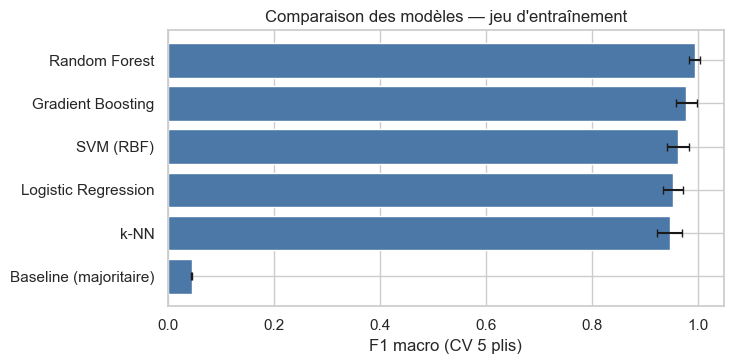

In [21]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
t = cv_table.sort_values("F1 macro (moy.)")
ax.barh(t.index, t["F1 macro (moy.)"], xerr=t["F1 macro (écart-type)"], color="#4c78a8", capsize=3)
ax.set(xlim=(0, 1.05), xlabel="F1 macro (CV 5 plis)", title="Comparaison des modèles — jeu d'entraînement")
plt.tight_layout(); plt.savefig(PLOTS / "10_model_comparison.png", dpi=150); plt.show()

### Réglage d'hyperparamètres

In [22]:
from sklearn.model_selection import GridSearchCV
GRIDS = {
    "Logistic Regression": {"clf__C": [0.1, 1, 10, 100]},
    "SVM (RBF)":           {"clf__C": [0.5, 1, 5, 20], "clf__gamma": ["scale", 0.05, 0.2]},
    "k-NN":                {"clf__n_neighbors": [3, 5, 7, 11], "clf__weights": ["uniform", "distance"]},
    "Random Forest":       {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 6, 12], "clf__min_samples_leaf": [1, 2]},
    "Gradient Boosting":   {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [2, 3]},
}
best_name = next(n for n in cv_table.index if n in GRIDS)      # meilleur modèle réel (hors baseline)
pipe = Pipeline([("prep", make_preprocessor()), ("clf", MODELS_CAND[best_name])])
gs = GridSearchCV(pipe, GRIDS[best_name], cv=cv, scoring="f1_macro", n_jobs=-1, refit=True)
gs.fit(X_train, y_train)
print("Modèle retenu            :", best_name)
print("Meilleurs hyperparamètres:", gs.best_params_)
print(f"F1 macro CV (réglé)      : {gs.best_score_:.3f}")
final_model = gs.best_estimator_      # Pipeline complet (prétraitement + classifieur), ajusté sur le train

Modèle retenu            : Random Forest
Meilleurs hyperparamètres: {'clf__max_depth': None, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 400}
F1 macro CV (réglé)      : 1.000


### Clustering non supervisé (K-means) — la structure existe-t-elle sans les étiquettes ?

In [23]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
Xp_train = Pipeline([("prep", make_preprocessor())]).fit_transform(X_train)
km = KMeans(n_clusters=6, n_init=20, random_state=RANDOM_STATE).fit(Xp_train)
print(f"Adjusted Rand Index K-means (6 clusters) vs vrais types : {adjusted_rand_score(y_train, km.labels_):.3f}")
print("(1 = partition identique, 0 = hasard)")

Adjusted Rand Index K-means (6 clusters) vs vrais types : 0.594
(1 = partition identique, 0 = hasard)


---
# 5 EVAL — Évaluation

**Objectif de l'étape** : mesurer la performance **sur le jeu de test**, jamais utilisé jusqu'ici (ni pour l'imputation, ni pour le choix du modèle, ni pour le réglage), puis comprendre où et pourquoi le modèle se trompe.

In [24]:
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
y_pred = final_model.predict(X_test)
metrics = {"accuracy": accuracy_score(y_test, y_pred),
           "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
           "f1_macro": f1_score(y_test, y_pred, average="macro")}
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Scores sur le jeu de test :", {k: round(v, 3) for k, v in metrics.items()})
print("Baseline (accuracy)       :", round(accuracy_score(y_test, base.predict(X_test)), 3))
print()
print(classification_report(y_test, y_pred, target_names=TYPE_ORDER, digits=3))

Scores sur le jeu de test : {'accuracy': 1.0, 'balanced_accuracy': np.float64(1.0), 'f1_macro': 1.0}
Baseline (accuracy)       : 0.167

               precision    recall  f1-score   support

  Brown Dwarf      1.000     1.000     1.000         8
    Red Dwarf      1.000     1.000     1.000         8
  White Dwarf      1.000     1.000     1.000         8
Main Sequence      1.000     1.000     1.000         8
   Supergiant      1.000     1.000     1.000         8
   Hypergiant      1.000     1.000     1.000         8

     accuracy                          1.000        48
    macro avg      1.000     1.000     1.000        48
 weighted avg      1.000     1.000     1.000        48



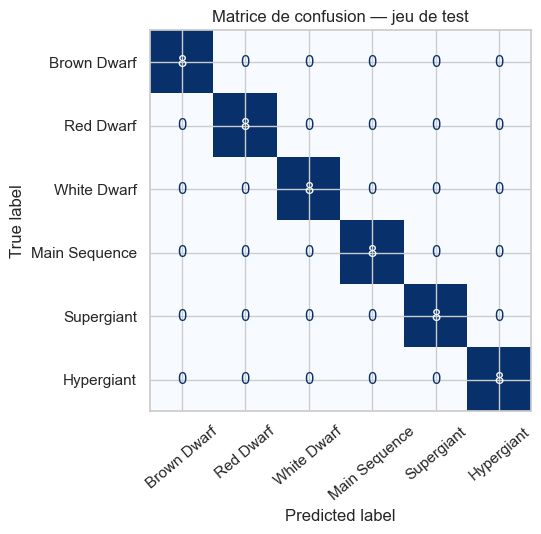

In [25]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=TYPE_ORDER, cmap="Blues",
                                        xticks_rotation=40, ax=ax, colorbar=False)
ax.set_title("Matrice de confusion — jeu de test"); plt.tight_layout()
plt.savefig(PLOTS / "11_confusion_matrix.png", dpi=150); plt.show()

### Importance des variables (permutation, sur le jeu de test)

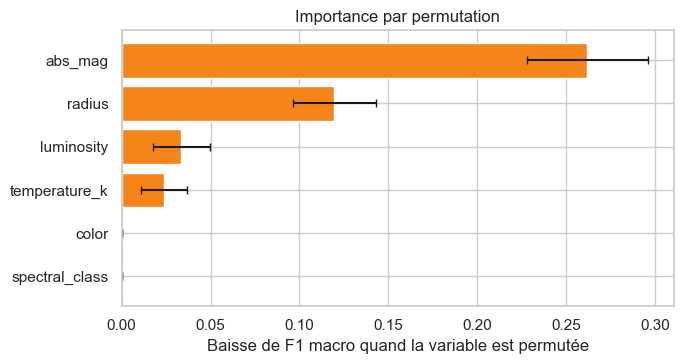

In [26]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(final_model, X_test, y_test, n_repeats=30, scoring="f1_macro",
                            random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
err = pd.Series(pi.importances_std, index=FEATURES)[imp.index]
plt.figure(figsize=(7, 3.8))
plt.barh(imp.index, imp.values, xerr=err.values, color="#f58518", capsize=3)
plt.xlabel("Baisse de F1 macro quand la variable est permutée")
plt.title("Importance par permutation"); plt.tight_layout()
plt.savefig(PLOTS / "12_permutation_importance.png", dpi=150); plt.show()

Les variables sont permutées sur leurs **colonnes brutes** (le pipeline embarque le prétraitement). Rappel : `abs_mag` et `luminosity` sont redondantes ; permuter l'une seule est partiellement compensée par l'autre, ce qui **sous-estime** l'importance de chacune.

### Analyse d'erreurs & robustesse

In [27]:
errors = X_test.assign(vrai=y_test.map(STAR_TYPES), prédit=pd.Series(y_pred, index=y_test.index).map(STAR_TYPES))
errors = errors[errors.vrai != errors.prédit]
print(f"{len(errors)} erreur(s) sur {len(X_test)} étoiles de test")
display(errors)

# Robustesse : le score dépend-il du découpage ? (validation croisée répétée sur TOUT le jeu)
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
sc = cross_val_score(final_model, X, y, cv=rcv, scoring="f1_macro")
print(f"F1 macro, CV 5x5 sur toutes les données : {sc.mean():.3f} ± {sc.std():.3f}  (min {sc.min():.3f})")

0 erreur(s) sur 48 étoiles de test


,temperature_k,luminosity,radius,abs_mag,color,spectral_class,vrai,prédit


F1 macro, CV 5x5 sur toutes les données : 0.998 ± 0.006  (min 0.979)


### Limites à retenir
- **Petit jeu de test (≈ 48 étoiles)** : un seul exemple mal classé change l'accuracy de ~2 points. La CV répétée ci-dessus est un indicateur plus stable que le score de test seul.
- **Jeu de données propre / partiellement synthétique** : classes parfaitement équilibrées et séparables ; les scores ne se généraliseront pas tels quels à un catalogue astronomique réel (classes très déséquilibrées, mesures plus bruitées).
- **Bruit dans `color` / `spectral_class`** (incohérences vues au §2.9) : ces variables apportent peu et peuvent induire en erreur.
- **Redondance** entre `luminosity`, `abs_mag`, `radius` et `temperature_k` (liées physiquement).

---
# Conclusion

- **Data** : 239 étoiles équilibrées ; les « manquants » étaient des espaces, invisibles pour `isnull()`.
- **EDA** : classes très séparables en (T, L, R) à condition de passer en échelle log ; quelques incohérences de données (couleurs, classes spectrales, loi de Stefan-Boltzmann).
- **Prétraitement** : tout dans un `Pipeline` sans fuite de données (log, imputation itérative, standardisation, one-hot).
- **ML** : 5 modèles comparés en validation croisée, meilleur modèle réglé.
- **EVAL** : scores sur test + CV répétée, matrice de confusion, importance par permutation, analyse d'erreurs et limites.